# Monthly Sales Forecasting

A classic time-series setup (trend + seasonality + noise), forecasting 12 months out on real data. The series is US retail trade sales, not seasonally adjusted, in millions of dollars (FRED series `RSXFSN`, from the Census Bureau's Monthly Retail Trade survey). I use the 60 months from January 2015 to December 2019 so the holdout year isn't the 2020 COVID shock, which no model trained on the prior years could see coming.

I'll fit a SARIMA baseline because Prophet is a bigger dependency and not everyone has it installed, and compare it with a seasonal naive forecast (same month last year), which is the bar any seasonal model has to clear.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

import warnings
warnings.filterwarnings("ignore")

from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error

DATA_DIR = Path("../../data/sales")

source: FRED RSXFSN  range: 2015-01-01 -> 2019-12-01  n=60


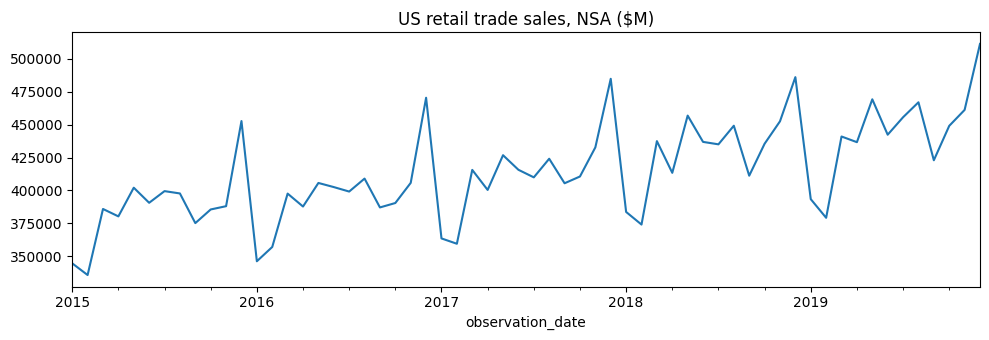

In [2]:
# US retail trade sales, NSA, millions of USD (FRED RSXFSN, source US Census Bureau)
csv = DATA_DIR / "RSXFSN.csv"
if not csv.exists():
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    pd.read_csv("https://fred.stlouisfed.org/graph/fredgraph.csv?id=RSXFSN").to_csv(csv, index=False)

full = pd.read_csv(csv, parse_dates=["observation_date"]).set_index("observation_date")["RSXFSN"]
series = full.loc["2015-01-01":"2019-12-01"].asfreq("MS").rename("sales")

print(f"source: FRED RSXFSN  range: {series.index.min().date()} -> {series.index.max().date()}  n={len(series)}")
series.plot(figsize=(10, 3.5), title="US retail trade sales, NSA ($M)"); plt.tight_layout(); plt.show()

In [3]:
# hold out the last 12 months as a test window
train, test = series.iloc[:-12], series.iloc[-12:]

# SARIMA(1,1,1)(1,1,1,12) is a reasonable starting point for monthly data with annual seasonality.
# I tried (0,1,1)(0,1,1,12) too, results were close.
model = SARIMAX(train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12),
                enforce_stationarity=False, enforce_invertibility=False)
res = model.fit(disp=False)
print(res.summary().tables[1])

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1652      0.385     -0.429      0.668      -0.920       0.589
ma.L1         -0.9546      0.155     -6.157      0.000      -1.258      -0.651
ar.S.L12       0.3348      0.413      0.810      0.418      -0.475       1.145
ma.S.L12      -0.0012      0.049     -0.025      0.980      -0.097       0.094
sigma2      5.508e+07   3.61e-09   1.53e+16      0.000    5.51e+07    5.51e+07


In [4]:
forecast = res.get_forecast(steps=12)
fc_mean = forecast.predicted_mean
ci = forecast.conf_int(alpha=0.2)  # 80% interval, easier to read than 95%

mae = mean_absolute_error(test, fc_mean)
mape = (np.abs(test - fc_mean) / test).mean() * 100
print(f"SARIMA          holdout MAE: {mae:,.0f}   MAPE: {mape:.2f}%")

# seasonal naive: each month of 2019 = same month of 2018
naive = pd.Series(train.iloc[-12:].values, index=test.index)
print(f"seasonal naive  holdout MAE: {mean_absolute_error(test, naive):,.0f}   "
      f"MAPE: {(np.abs(test - naive) / test).mean() * 100:.2f}%")
inside = ((test >= ci.iloc[:, 0]) & (test <= ci.iloc[:, 1])).mean()
print(f"share of holdout months inside the 80% band: {inside:.0%}")

SARIMA          holdout MAE: 9,525   MAPE: 2.17%
seasonal naive  holdout MAE: 13,100   MAPE: 2.90%
share of holdout months inside the 80% band: 42%


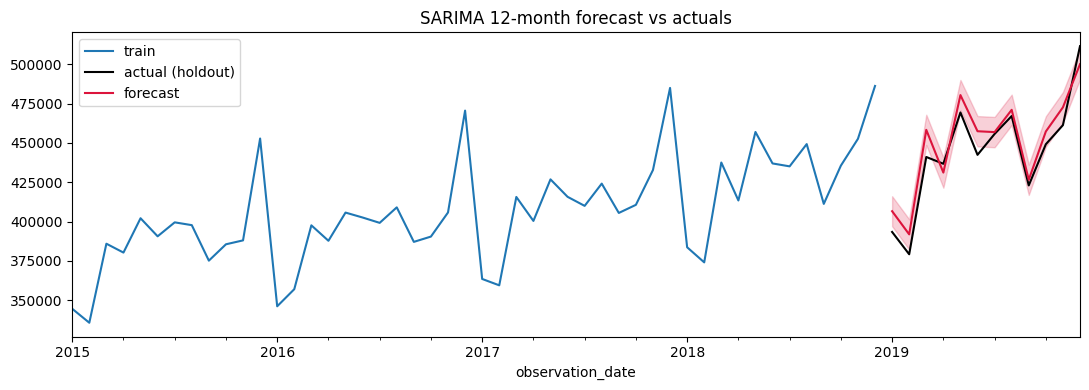

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
train.plot(ax=ax, label="train")
test.plot(ax=ax, label="actual (holdout)", color="black")
fc_mean.plot(ax=ax, label="forecast", color="crimson")
ax.fill_between(fc_mean.index, ci.iloc[:, 0], ci.iloc[:, 1], alpha=0.2, color="crimson")
ax.legend(); ax.set_title("SARIMA 12-month forecast vs actuals")
plt.tight_layout(); plt.show()

## What I learned

On the 2019 holdout, SARIMA(1,1,1)(1,1,1,12) gets a MAPE of 2.17% (MAE about $9.5B per month), which beats the seasonal naive forecast at 2.90% (MAE about $13.1B). So the model is adding something over "same month last year", mostly by picking up the upward trend.

The 80% band is the part I'd trust least. Only 5 of the 12 holdout months (42%) fall inside it, when an honest 80% interval should cover about 10. With 48 training months the model underestimates its own uncertainty, and anybody planning off the December number needs to know the real range is wider than the plot shows.

Things I'd want to do before trusting this for real planning:
- Cross-validate with a rolling-origin scheme, not just one holdout. A single 12-month tail can be lucky.
- Check residual autocorrelation. If the residuals still have structure I'm leaving signal on the table.
- Model the series in logs and add calendar effects (trading days, Easter moving between March and April). Prophet handles holidays cleanly, and a gradient-boosted model on lag features is worth a try. Ensembling them often beats any one of them.